In [27]:
import pandas as pd
df = pd.read_csv("clean.csv")
df.head()

,id,host_id,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,has_reviews
0,2539,2787,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,0.21,6,365,1
1,2595,2845,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,0.38,2,355,1
2,3647,4632,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,0.00,1,365,0
3,3831,4869,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,4.64,1,194,1
4,5022,7192,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,0.10,1,0,1


### الاكتشاف 1: السعر حسب نوع الغرفة
الوسيط لـ Entire home/apt هو 160 دولار مقابل 45 دولار لـ Shared room، أي أعلى بنسبة 256%.

**ماذا يعني للعميل؟** يسعّر المضيف إعلانه حسب نوع الغرفة، ولا يستخدم سعراً واحداً لكل الأنواع.

In [28]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48631 entries, 0 to 48630
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48631 non-null  int64  
 1   host_id                         48631 non-null  int64  
 2   neighbourhood_group             48631 non-null  object 
 3   neighbourhood                   48631 non-null  object 
 4   latitude                        48631 non-null  float64
 5   longitude                       48631 non-null  float64
 6   room_type                       48631 non-null  object 
 7   price                           48631 non-null  int64  
 8   minimum_nights                  48631 non-null  int64  
 9   number_of_reviews               48631 non-null  int64  
 10  reviews_per_month               48631 non-null  float64
 11  calculated_host_listings_count  48631 non-null  int64  
 12  availability_365                

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,has_reviews
count,4.863100e+04,4.863100e+04,48631.000000,48631.000000,48631.000000,48631.000000,48631.000000,48631.000000,48631.000000,48631.000000,48631.000000
mean,1.901839e+07,6.762227e+07,40.728938,-73.952049,141.312866,6.782937,23.360038,1.094834,7.164216,112.391540,0.796200
std,1.097952e+07,7.860380e+07,0.054572,0.046171,116.737448,16.123039,44.636278,1.599551,33.031242,131.403672,0.402826
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,10.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,9.475315e+06,7.828522e+06,40.690020,-73.982980,69.000000,1.000000,1.000000,0.040000,1.000000,0.000000,1.000000
50%,1.967517e+07,3.082680e+07,40.722970,-73.955600,105.000000,3.000000,5.000000,0.380000,1.000000,44.000000,1.000000
75%,2.914624e+07,1.074344e+08,40.763130,-73.936120,175.000000,5.000000,24.000000,1.590000,2.000000,225.000000,1.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,1000.000000,365.000000,629.000000,58.500000,327.000000,365.000000,1.000000


### الاكتشاف 2: السعر حسب المنطقة
الوسيط في Manhattan هو 149 دولار مقابل 65 دولار في Bronx، أي أعلى بنسبة 129%.

**ماذا يعني للعميل؟** يسعّر المضيف حسب منطقته، ولا يستخدم سعراً موحداً لكل نيويورك.

In [29]:
print(df["room_type"].value_counts())
print(df["neighbourhood_group"].value_counts())
print(df["price"].describe())
print(df[df["price"] == 0].shape[0])

room_type
Entire home/apt    25207
Private room       22269
Shared room         1155
Name: count, dtype: int64
neighbourhood_group
Manhattan        21482
Brooklyn         20035
Queens            5654
Bronx             1089
Staten Island      371
Name: count, dtype: int64
count    48631.000000
mean       141.312866
std        116.737448
min         10.000000
25%         69.000000
50%        105.000000
75%        175.000000
max       1000.000000
Name: price, dtype: float64
0


**ماذا يعني للعميل؟** الإعلانات التي لها تقييمات أرخص في الوسيط داخل كل نوع غرفة (150 مقابل 190 دولار في Entire home/apt)، فالفرق ليس سببه نوع الغرفة. لكن لا تثبت الداتا أن التقييمات هي السبب، فقد تكون المنطقة أو عمر الإعلان.

In [30]:
print(df.groupby(["room_type", "has_reviews"])["price"].median())

room_type        has_reviews
Entire home/apt  0              190.0
                 1              150.0
Private room     0               75.0
                 1               70.0
Shared room      0               50.0
                 1               45.0
Name: price, dtype: float64


room_type
Shared room         45.0
Private room        70.0
Entire home/apt    160.0
Name: price, dtype: float64


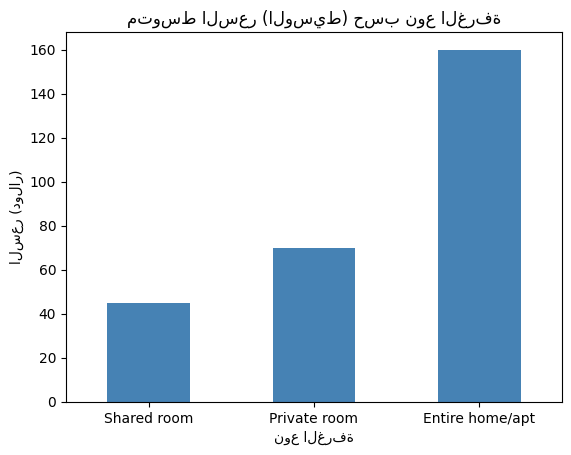

In [31]:
import matplotlib.pyplot as plt

r = df.groupby("room_type")["price"].median().sort_values()
print(r)

r.plot(kind="bar", color="steelblue")
plt.title("متوسط السعر (الوسيط) حسب نوع الغرفة")
plt.xlabel("نوع الغرفة")
plt.ylabel("السعر (دولار)")
plt.xticks(rotation=0)
plt.show()

### الاكتشاف 4: الحد الأدنى لليالي
الإعلانات بحد أدنى ليلة واحدة تأخذ 1.61 تقييم شهرياً مقابل 0.32 للتي حدها الأدنى 30 ليلة فأكثر، أي أكثر بنحو 5 أضعاف.

**ماذا يعني للعميل؟** المضيف الذي يريد حجوزات أكثر يخفض الحد الأدنى لليالي.

neighbourhood_group
Bronx             65.0
Queens            75.0
Staten Island     75.0
Brooklyn          90.0
Manhattan        149.0
Name: price, dtype: float64


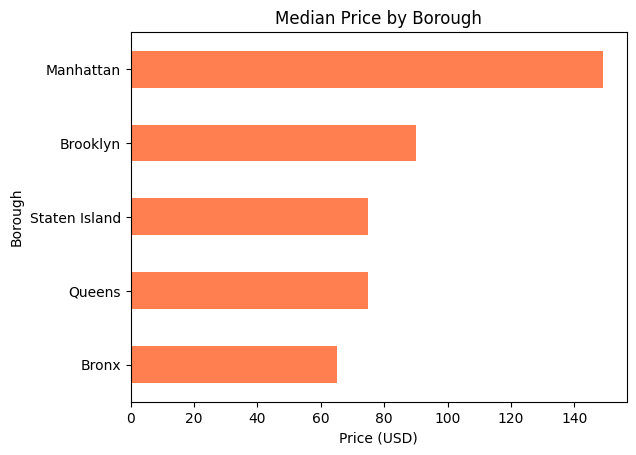

In [32]:
n = df.groupby("neighbourhood_group")["price"].median().sort_values()
print(n)

n.plot(kind="barh", color="coral")
plt.title("Median Price by Borough")
plt.xlabel("Price (USD)")
plt.ylabel("Borough")
plt.show()

### الاكتشاف 5: التوفر خلال السنة
متوسط التوفر لـ Shared room هو 162 يوم في السنة مقابل 111 يوم لـ Private room.

**ماذا يعني للعميل؟** الغرف المشتركة تبقى متاحة أياماً أكثر (أي حجوزاتها أقل)، فعلى المضيف ألا يتوقع منها دخلاً ثابتاً.

In [33]:
df["min_group"] = pd.cut(df["minimum_nights"], [0, 1, 3, 7, 30, 1500],
                         labels=["1", "2-3", "4-7", "8-30", "30+"])

def pct(hi, lo):
    return (hi - lo) / lo * 100

r = df.groupby("room_type")["price"].median()
n = df.groupby("neighbourhood_group")["price"].median()
g = df.groupby("has_reviews")["price"].median()
m = df.groupby("min_group", observed=True)["reviews_per_month"].mean()
a = df.groupby("room_type")["availability_365"].mean()

print(f"1) الوسيط لـ {r.idxmax()} هو {r.max():.0f} دولار مقابل {r.min():.0f} دولار لـ {r.idxmin()}، أي أعلى بنسبة {pct(r.max(), r.min()):.0f}%.\n")

print(f"2) الوسيط في {n.idxmax()} هو {n.max():.0f} دولار مقابل {n.min():.0f} دولار في {n.idxmin()}، أي أعلى بنسبة {pct(n.max(), n.min()):.0f}%.\n")

print(f"3) الوسيط للإعلانات التي لها تقييمات هو {g[1]:.0f} دولار مقابل {g[0]:.0f} دولار للتي بدون تقييمات.\n")

print(f"4) الإعلانات بحد أدنى 1 ليلة تأخذ {m.iloc[0]:.2f} تقييم شهرياً مقابل {m.iloc[-1]:.2f} للتي حدها الأدنى 30+ ليلة.\n")

print(f"5) متوسط التوفر لـ {a.idxmax()} هو {a.max():.0f} يوم في السنة مقابل {a.min():.0f} يوم لـ {a.idxmin()}.")

1) الوسيط لـ Entire home/apt هو 160 دولار مقابل 45 دولار لـ Shared room، أي أعلى بنسبة 256%.

2) الوسيط في Manhattan هو 149 دولار مقابل 65 دولار في Bronx، أي أعلى بنسبة 129%.

3) الوسيط للإعلانات التي لها تقييمات هو 100 دولار مقابل 120 دولار للتي بدون تقييمات.

4) الإعلانات بحد أدنى 1 ليلة تأخذ 1.61 تقييم شهرياً مقابل 0.32 للتي حدها الأدنى 30+ ليلة.

5) متوسط التوفر لـ Shared room هو 162 يوم في السنة مقابل 111 يوم لـ Private room.


In [34]:
df["min_group"] = pd.cut(df["minimum_nights"], [0, 1, 3, 7, 30, 1500],
                         labels=["1", "2-3", "4-7", "8-30", "30+"])
pct = lambda hi, lo: (hi - lo) / lo * 100

r = df.groupby("room_type")["price"].median()
n = df.groupby("neighbourhood_group")["price"].median()
g = df.groupby("has_reviews")["price"].median()
m = df.groupby("min_group", observed=True)["reviews_per_month"].mean()
a = df.groupby("room_type")["availability_365"].mean()

print("1) room:", r.idxmax(), round(r.max()), "vs", r.idxmin(), round(r.min()), "| diff %", round(pct(r.max(), r.min())))
print("2) borough:", n.idxmax(), round(n.max()), "vs", n.idxmin(), round(n.min()), "| diff %", round(pct(n.max(), n.min())))
print("3) reviews: with", round(g[1]), "vs without", round(g[0]))
print("4) min nights: 1 night", round(m.iloc[0], 2), "vs 30+", round(m.iloc[-1], 2))
print("5) availability:", a.idxmax(), round(a.max()), "vs", a.idxmin(), round(a.min()))

1) room: Entire home/apt 160 vs Shared room 45 | diff % 256
2) borough: Manhattan 149 vs Bronx 65 | diff % 129
3) reviews: with 100 vs without 120
4) min nights: 1 night 1.61 vs 30+ 0.32
5) availability: Shared room 162 vs Private room 111


## القسم 9: التوصيات

**التوصية 1: سعّر حسب المنطقة ونوع الغرفة.**
الوسيط في Manhattan هو 149 دولار مقابل 65 دولار في Bronx (أعلى بنسبة 129%)، وفي Entire home/apt هو 160 دولار مقابل 45 دولار في Shared room. لذلك لا يُستخدم سعر موحد، بل يُحدد السعر بمقارنة إعلانات من نفس المنطقة ونفس نوع الغرفة.

**التوصية 2: خفّض الحد الأدنى لليالي إذا كان الهدف حجوزات أكثر.**
الإعلانات بحد أدنى ليلة واحدة تأخذ 1.61 تقييم شهرياً مقابل 0.32 للتي حدها الأدنى 30 ليلة فأكثر. فيُنصح المضيف الذي يريد نشاطاً أعلى بتجربة حد أدنى أقل (1 إلى 3 ليال).

**التوصية 3: لا تتوقع دخلاً ثابتاً من الغرف المشتركة.**
متوسط التوفر لـ Shared room هو 162 يوم في السنة مقابل 111 يوم لـ Private room، أي أنها متاحة أياماً أكثر. فيُخطَّط للدخل منها بحذر.

**ما لا تستطيع الداتا قوله:**
الارتباط ليس سببًا. مثلاً، الإعلانات التي لها تقييمات أرخص داخل كل نوع غرفة (150 مقابل 190 دولار في Entire home/apt)، لكن الداتا لا تثبت أن التقييمات هي السبب، فقد تكون المنطقة أو عمر الإعلان. وكذلك لا تثبت أن خفض الحد الأدنى لليالي سيزيد التقييمات، لأنها تقارن إعلانات مختلفة ولا تجرّب التغيير نفسه.